# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [24]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV

In [25]:
# Twoje rozwiązanie
try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)                                   # DatasetDict: train / test / unsupervised
    train_df = imdb["train"].to_pandas()          # kolumny: text, label
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)
train_df.head()

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [26]:
def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)

train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])
print("recenzji z '<br />' po czyszczeniu:", train_df["text"].str.contains("<br />").sum())

recenzji z '<br />' po czyszczeniu: 0


In [27]:
class_share = train_df["label"].value_counts(normalize=True)
lenghts = train_df["text"].str.split().str.len()
median_words = lenghts.median()

print(class_share)
print(f"min slow: {lenghts.min()}, max słow {lenghts.max()}")
print(median_words)

label
0    0.5
1    0.5
Name: proportion, dtype: float64
min slow: 10, max słow 2459
173.0


In [28]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [29]:
# Twoje rozwiązanie
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000)
}
wiersze = []
for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), train_df["text"], train_df["label"], cv=cv, return_train_score=True)
    wiersze.append({"model": nazwa, "CV": r["test_score"].mean(), "CV odch.": r["test_score"].std(),
                     "czas uczenia [s]": r["fit_time"].mean()})
porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)

,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.862,0.002,3.762
liniowy SVM,0.893,0.001,4.386
regresja logistyczna,0.885,0.002,6.202


In [30]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

5 krotne zwiekszenie zbioru treningowego znacznie wydluzylo czas uczenia, 5 krotnie zmniejszylo odchylenie (w przypadku liniowym 10 krotnie) i zwiekszylo CV o ~0.04. Kolejnosc modeli pozostala bez zmian.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [31]:
# Twoje rozwiązanie
pipe_svm = make_pipeline(TfidfVectorizer(min_df=2), LinearSVC())
param_grid  = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1]
}
gs = GridSearchCV(pipe_svm, param_grid, cv=cv)
gs.fit( train_df["text"], train_df['label'])
print("Najlepszy parametry: ", gs.best_params_)
print(f"Najlepszy wynik: {gs.best_score_:.4f}")
pd.DataFrame(gs.cv_results_)[[
    "param_tfidfvectorizer__ngram_range",
    "param_linearsvc__C",
    "mean_test_score",
    "mean_fit_time"
]].round(4)




Najlepszy parametry:  {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
Najlepszy wynik: 0.9064


,param_tfidfvectorizer__ngram_range,param_linearsvc__C,mean_test_score,mean_fit_time
0,"(1, 1)",0.1,0.8876,3.6734
1,"(1, 2)",0.1,0.8891,11.3740
2,"(1, 1)",1.0,0.8922,4.5756
3,"(1, 2)",1.0,0.9064,11.2751


In [32]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

na małym zbiorze rzadkie pary slow wystepowaly sporadycznie, natomiast na zbiorze 25000 recenzji pojawiaja sie czesciej i pomagaja (widac to w sredniej dokladnosci walidacji krzyzowej ktora rosnie z 0.89 do 0.9). Model z bigramami uczy sie okolo 5 razy wolniej. Spowodowane jest to faktem iz rosnie slownik i liczba kolumn macierzy, a kazda recenzja ma sporo wiecej niezerowych cech.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy na zbiorze testowym: 0.9030


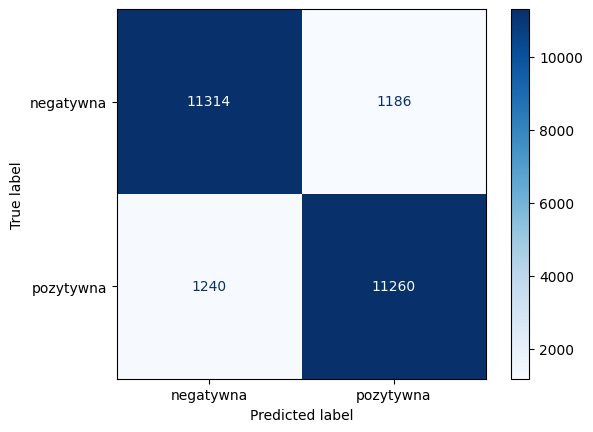

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [33]:
# Twoje rozwiązanie
model_koncowy = gs.best_estimator_
y_pred = model_koncowy.predict(test_df["text"])
acc_test = model_koncowy.score(test_df['text'], test_df['label'])
print(f"accuracy na zbiorze testowym: {acc_test:.4f}")
ConfusionMatrixDisplay.from_predictions(
    test_df['label'], y_pred, cmap="Blues",
    display_labels=["negatywna", "pozytywna"]
)
plt.show()
print(classification_report(test_df["label"], y_pred, target_names=["negatywna", "pozytywna"], digits = 3))

In [34]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

15 cech o najmniejszej wadze:
worst            -4.1869
awful            -3.7180
bad              -3.6400
boring           -3.4614
poor             -3.2703
the worst        -3.1834
waste            -2.9195
disappointment   -2.6049
terrible         -2.5830
worse            -2.5669
poorly           -2.5107
disappointing    -2.4630
dull             -2.4201
unfortunately    -2.3958
annoying         -2.3332
dtype: float64

15 cech o najwiekszej wadze:
best         1.8353
favorite     1.8540
bit          1.8560
loved        1.8763
superb       1.9061
brilliant    1.9452
the best     1.9554
enjoyable    1.9650
today        2.2036
amazing      2.2084
fun          2.2861
wonderful    2.5659
perfect      2.7518
excellent    3.2366
great        3.5712
dtype: float64


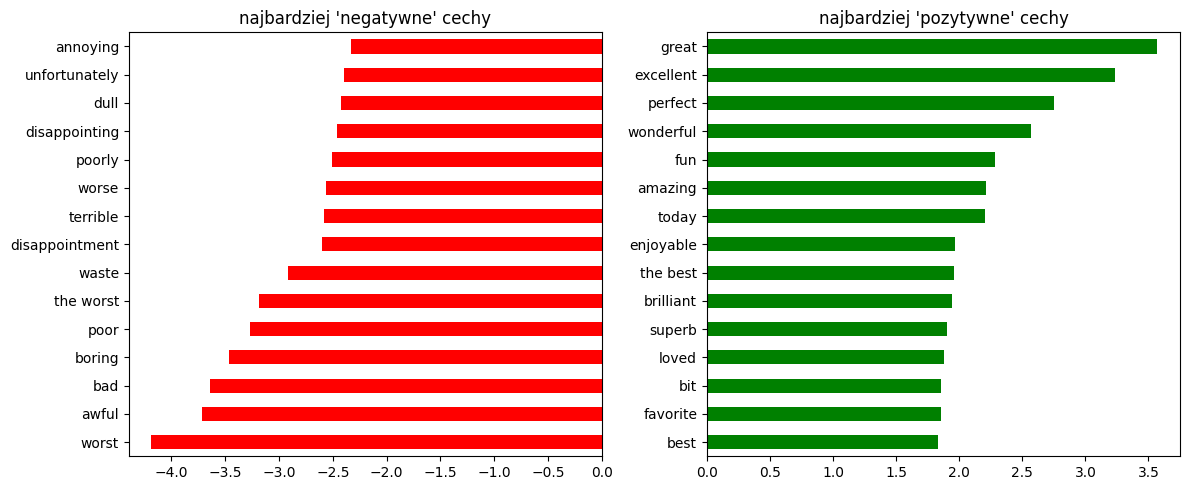


Liczba błedów: 2426 / 25000
1. prawdziwa: 0, predykcja: 1
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other action guys (Segal and Dolph) have thought about putting out the past few years. Van Damme is good in the movie, the movie is only worth watching to Van Damme fans. It is not as good as Wake of Death (whi...

2. prawdziwa: 0, predykcja: 1
Ben, (Rupert Grint), is a deeply unhappy adolescent, the son of his unhappily married parents. His father, (Nicholas Farrell), is a vicar and his mother, (Laura Linney), is ... well, let's just say she's a somewhat hypocritical soldier in Jesus' army. It's only when he takes a summer job as an assistant to a foul-mouthed, eccentric, once-famous and now-forgotten actress Evie Walton, (Julie Walters), tha

In [35]:
# Twoje rozwiązanie
words = model_koncowy[0].get_feature_names_out()
wagi = pd.Series(model_koncowy[-1].coef_[0], index = words).sort_values()
print("15 cech o najmniejszej wadze:")
print(wagi.head(15).round(4))
print("\n15 cech o najwiekszej wadze:")
print(wagi.tail(15).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12,5))
wagi.head(15).plot.barh(ax=axes[0], color = "red", title="najbardziej 'negatywne' cechy")
wagi.tail(15).plot.barh(ax=axes[1], color = "green", title="najbardziej 'pozytywne' cechy")
fig.tight_layout()
plt.show()

bledy = test_df.assign(pred=y_pred)[y_pred != test_df["label"].values]
print(f"\nLiczba błedów: {len(bledy)} / {len(test_df)}")
for idx, (_,row) in enumerate(bledy.head(3).iterrows(), 1):
  print(f"{idx}. prawdziwa: {row['label']}, predykcja: {row['pred']}\n{row['text'][:500]}...\n")
recenzje = [
    "This sci-fi masterpiece completely blew me away. The visual effects are breathtaking, the soundtrack is deeply moving, and the lead performance is easily an Oscar-worthy turn. A cinema trip you won't forget!",
    "A painful waste of two hours. The plot is predictable, the dialogue feels entirely unnatural, and the main characters are completely unbearable. Save your money and skip this disaster.",
    "The reboot is not terrible by any means, and the CGI isn't half bad. However, it never quite manages to be genuinely thrilling or truly memorable.",
    "Truly groundbreaking filmmaking! I especially loved how the script solved every major conflict with a convenient miracle just as the pacing completely died. Pure artistic genius.",
    "The cinematography is gorgeous and the musical score builds incredible tension. Unfortunately, the rushed third act leaves too many plot holes open to fully satisfy."
]
print("\nPredykcja dla własnych recenzji")
predykcje = model_koncowy.predict(recenzje)
wyniczki = model_koncowy.decision_function(recenzje)
for tekst, pred, wynik in zip(recenzje, predykcje, wyniczki):
  etykieta = "pozytywna (1)" if pred == 1 else "negatywna (0)"
  print(f"{etykieta:14s} [wynik SVM = {wynik:+.2f}] {tekst}")


In [36]:
y_test = test_df["label"]

In [37]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

1. Bigramy jakie sie pojawily to "the best" oraz "the worst". Świadczy to o fakcie iż model nauczył się uwzględniać frazy zlożone z dwóch słów.

2. Recenzje sa negatywne, które model sklasyfikowal jako pozytywne. Pierwsza recenzja ma sporo pozytywnych slów, druga to zarys fabuły, trzecia recenzja krytkuje gre aktorska ale reszta ma pozytywny wydzwiek. Człowiek również mógłby mieć problem z ocenaą

3. Model zle ocenił 4 recenzje, która zawiera sarkazm.

4. Model Bag-of-Words nie analizuje kolejności słów, struktury gramatycznej, zależności długodystansowych ani kontekstu (sarkazm, ironia, ton wypowiedzi). Sumuje jedynie wagi poszczególnych cech. Model musiałby opierać się bardziej na kontekście.